In [28]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("Imports successful")
print("Scikit-learn version:", sklearn.__version__)
sns.set_theme(style="whitegrid")

Imports successful
Scikit-learn version: 1.9.1


In [29]:
possible_paths = [
    Path("data/diabetes.csv"),
    Path("../data/diabetes.csv"),
]

csv_path = next((path for path in possible_paths if path.exists()), None)

if csv_path is None:
    raise FileNotFoundError(
        "Could not find diabetes.csv. Put it in a data folder beside the notebook "
        "or in the project root's data folder."
    )

df = pd.read_csv(csv_path)

print(f"Loaded: {csv_path}")
display(df.head())

Loaded: data\diabetes.csv


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [31]:
print("Rows and columns:", df.shape)
print("\nColumn information:")
df.info()

print("\nMissing values already encoded as NaN:")
display(df.isna().sum().to_frame("missing_count"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget counts:")
display(df["Outcome"].value_counts().sort_index().rename(index={0: "Outcome 0", 1: "Outcome 1"}))

Rows and columns: (768, 9)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Missing values already encoded as NaN:


,missing_count
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0



Duplicate rows: 0

Target counts:


Outcome
Outcome 0    500
Outcome 1    268
Name: count, dtype: int64

In [32]:
display(df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


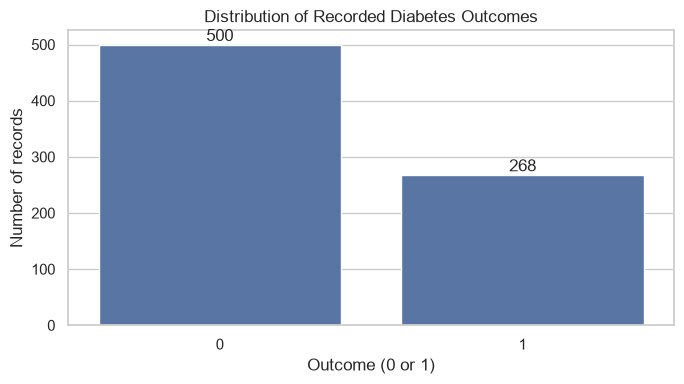

In [33]:
plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df, x="Outcome")
ax.set_title("Distribution of Recorded Diabetes Outcomes")
ax.set_xlabel("Outcome (0 or 1)")
ax.set_ylabel("Number of records")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()

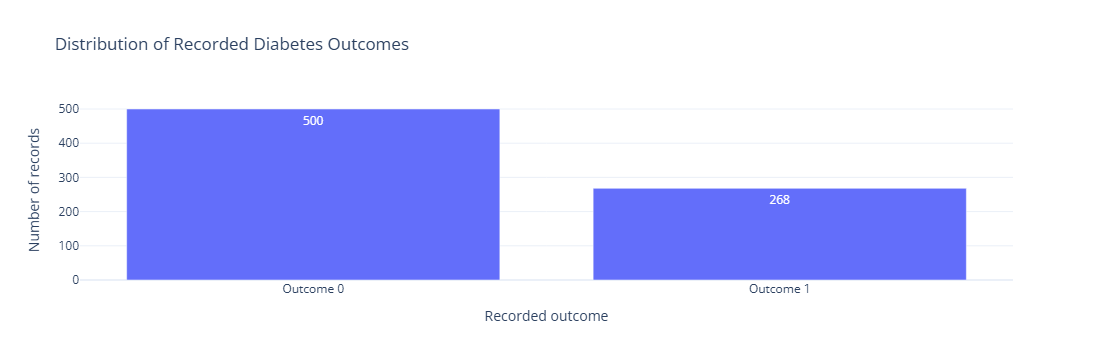

In [34]:
outcome_counts = (
    df["Outcome"].value_counts().sort_index()
    .rename_axis("Outcome").reset_index(name="Count")
)
outcome_counts["Outcome label"] = outcome_counts["Outcome"].map({
    0: "Outcome 0", 1: "Outcome 1"
})

fig = px.bar(
    outcome_counts,
    x="Outcome label",
    y="Count",
    text="Count",
    title="Distribution of Recorded Diabetes Outcomes",
    labels={"Outcome label": "Recorded outcome", "Count": "Number of records"}
)
fig.update_layout(template="plotly_white")
fig.show()

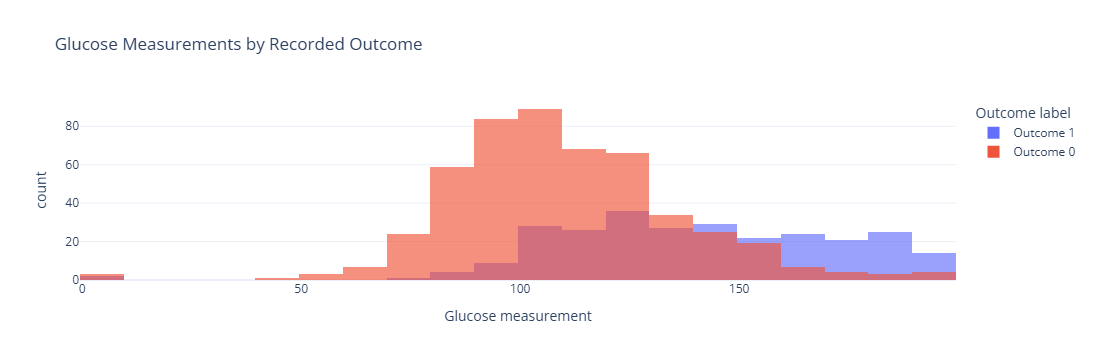

In [36]:
df_plot = df.copy()
df_plot["Outcome label"] = df_plot["Outcome"].map({
    0: "Outcome 0", 1: "Outcome 1"
})

fig = px.histogram(
    df_plot, x="Glucose", color="Outcome label",
    nbins=25, barmode="overlay", opacity=0.65,
    title="Glucose Measurements by Recorded Outcome",
    labels={"Glucose": "Glucose measurement", "count": "Number of records"}
)
fig.update_layout(template="plotly_white")
fig.show()

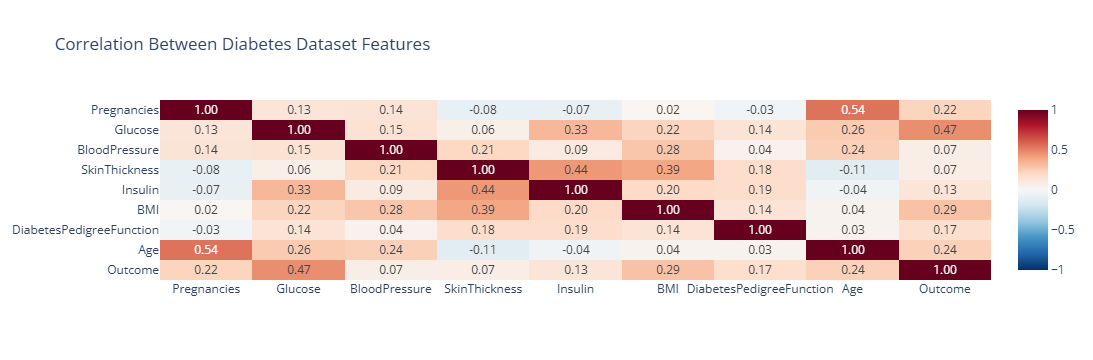

In [37]:
import plotly.express as px

correlation = df.corr(numeric_only=True)

fig = px.imshow(
    correlation,
    text_auto=".2f",
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1,
    aspect="auto",
    title="Correlation Between Diabetes Dataset Features"
)

fig.update_layout(template="plotly_white")
fig.show()

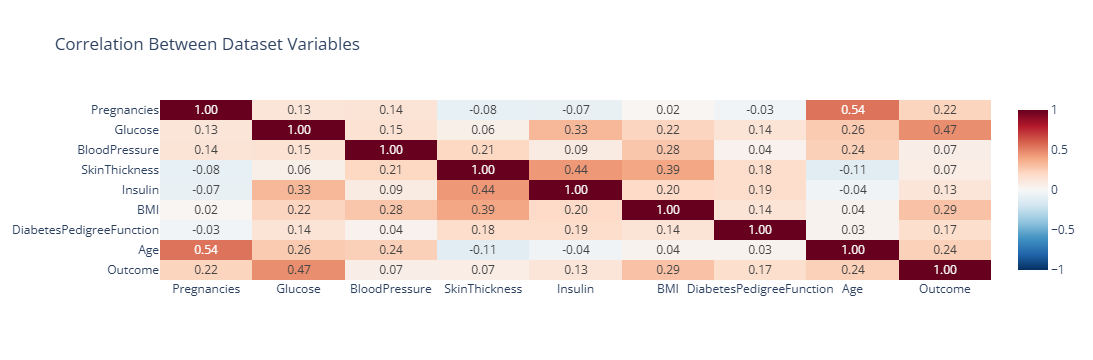

In [39]:
correlation = df.corr(numeric_only=True)

fig = px.imshow(
    correlation,
    text_auto=".2f",
    color_continuous_scale="RdBu_r",
    zmin=-1, zmax=1, aspect="auto",
    title="Correlation Between Dataset Variables"
)
fig.update_layout(template="plotly_white")
fig.show()

,zero_count,percent_of_rows
Glucose,5,0.65
BloodPressure,35,4.56
SkinThickness,227,29.56
Insulin,374,48.70
BMI,11,1.43


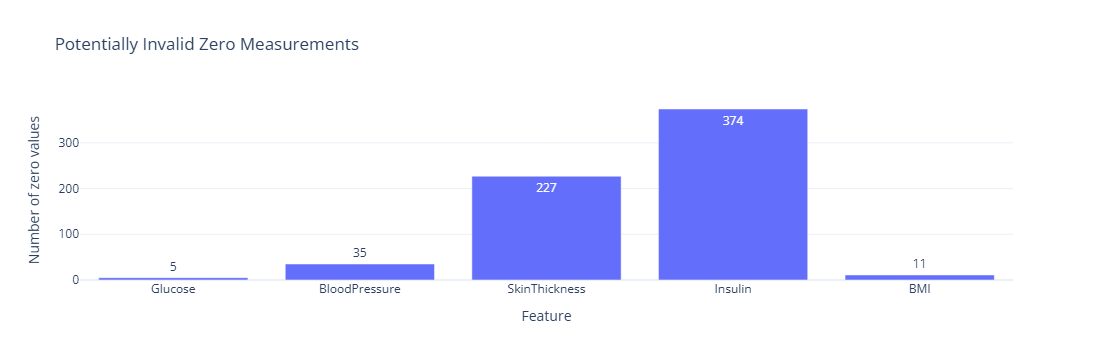

In [41]:
columns_with_suspicious_zeros = [
    "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"
]

zero_counts = (
    df[columns_with_suspicious_zeros].eq(0).sum()
    .rename("zero_count").to_frame()
)
zero_counts["percent_of_rows"] = (zero_counts["zero_count"] / len(df) * 100).round(2)
display(zero_counts)

fig = px.bar(
    zero_counts.reset_index(names="Feature"),
    x="Feature", y="zero_count", text="zero_count",
    title="Potentially Invalid Zero Measurements",
    labels={"zero_count": "Number of zero values", "Feature": "Feature"}
)
fig.update_layout(template="plotly_white")
fig.show()

In [42]:
data = df.copy()

data[columns_with_suspicious_zeros] = data[columns_with_suspicious_zeros].replace(0, np.nan)

print("Missing values after zero handling:")
display(data.isna().sum().to_frame("missing_count"))

print("Missing percentage:")
display((data.isna().mean() * 100).round(2).to_frame("missing_percent"))

Missing values after zero handling:


,missing_count
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


Missing percentage:


,missing_percent
Pregnancies,0.00
Glucose,0.65
BloodPressure,4.56
SkinThickness,29.56
Insulin,48.70
BMI,1.43
DiabetesPedigreeFunction,0.00
Age,0.00
Outcome,0.00


In [44]:
X = data.drop(columns="Outcome")
y = data["Outcome"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget proportions:")
display(y.value_counts(normalize=True).sort_index().rename(index={0: "Outcome 0", 1: "Outcome 1"}).mul(100).round(2).to_frame("percent"))

Features shape: (768, 8)
Target shape: (768,)

Target proportions:


,percent
Outcome,
Outcome 0,65.1
Outcome 1,34.9


In [54]:
# from sklearn.model_selection import train_test_split

X = data.drop(columns=["Outcome"])
y = data["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 614
Testing records: 154


In [46]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.708
ROC-AUC: 0.813

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



In [55]:
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

print("Logistic Regression model is ready!")

Logistic Regression model is ready!


In [56]:
results = []
fitted_models = {}

for name, estimator in models.items():
    estimator.fit(X_train, y_train)
    fitted_models[name] = estimator

    predictions = estimator.predict(X_test)
    probabilities = estimator.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (class 1)": precision_score(y_test, predictions, zero_division=0),
        "Recall (class 1)": recall_score(y_test, predictions, zero_division=0),
        "F1 (class 1)": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results).set_index("Model").sort_values("ROC-AUC", ascending=False)
display(results_df.round(3))

,Accuracy,Precision (class 1),Recall (class 1),F1 (class 1),ROC-AUC
Model,,,,,
Logistic Regression,0.708,0.600,0.500,0.545,0.813
Random Forest,0.753,0.682,0.556,0.612,0.812
Decision Tree,0.708,0.605,0.481,0.536,0.731


In [57]:
baseline = fitted_models["Logistic Regression"]
baseline_pred = baseline.predict(X_test)
baseline_prob = baseline.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test, baseline_pred,
    target_names=["Outcome 0", "Outcome 1"],
    zero_division=0
))

              precision    recall  f1-score   support

   Outcome 0       0.75      0.82      0.78       100
   Outcome 1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



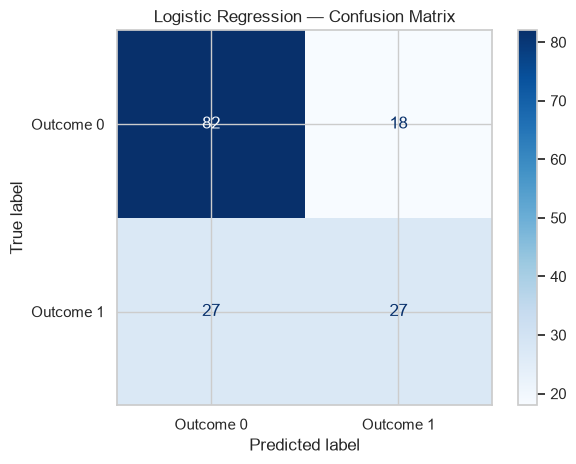

In [58]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    baseline_pred,
    display_labels=["Outcome 0", "Outcome 1"],
    cmap="Blues",
    values_format="d"
)
plt.title("Logistic Regression — Confusion Matrix")
plt.tight_layout()
plt.show()

In [62]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score
import joblib
import os

# Separate features and target
X = data.drop(columns=["Outcome"])
y = data["Outcome"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train the model
model.fit(X_train, y_train)

# Evaluate the model
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Save the trained pipeline
os.makedirs("./models", exist_ok=True)
joblib.dump(model, "./models/diabetes_model.joblib")

print("Model saved successfully!")

Accuracy: 0.7077922077922078
ROC-AUC: 0.812962962962963

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154

Model saved successfully!
